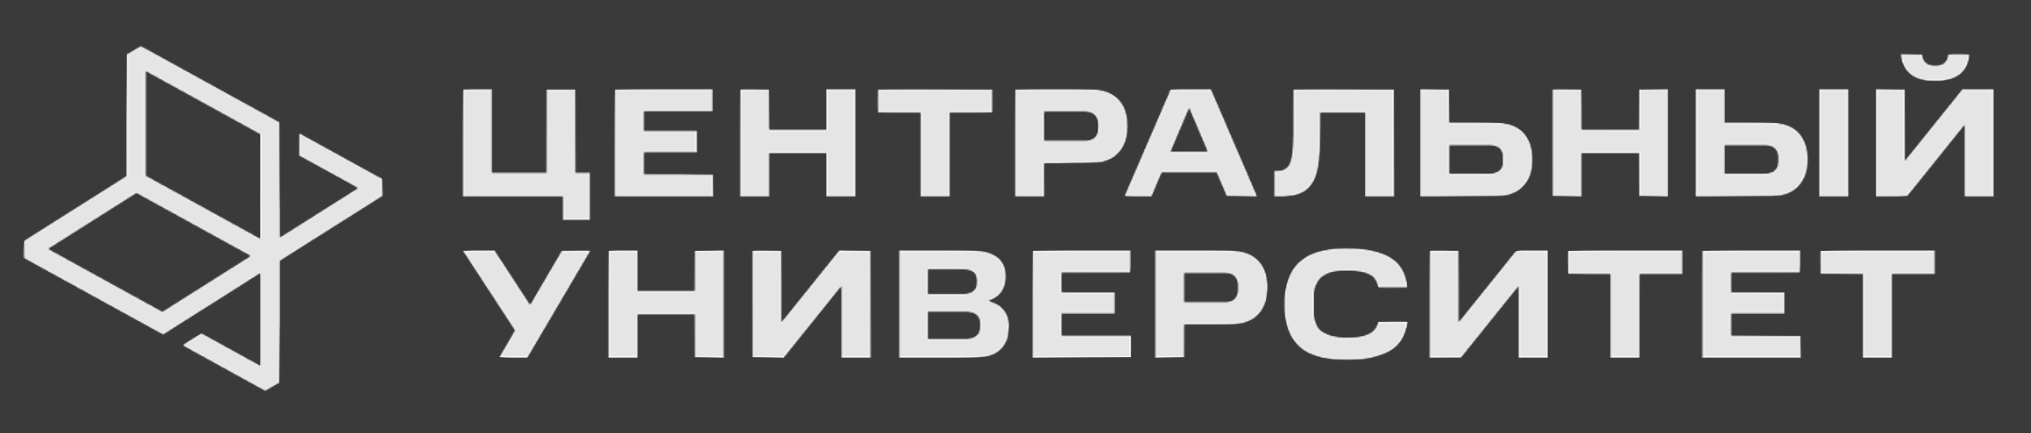

# Курс по прогнозированию временных рядов

# Неделя 10

## 10.3.1. N-BEATS: Neural Basis Expansion Analysis for Time Series.

Мы будем использовать PyTorch-реализацию N-BEATS в библиотеке-обертке Darts.  Darts облегчает переключение между методами прогнозирования, предварительную обработку и оценку качества.

Будем прогнозировать почасовые цены на электроэнергию в Испании. Временной ряд демонстрирует три сезонных паттерна: часы, дни недели и месяцы. Более 30 экзогенных переменных влияют на уровень цен.

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

Хороший пример использования библиотеки Darts https://www.kaggle.com/code/ferdinandberr/darts-forecasting-deep-learning-global-models/notebook
Обязательно посмотрите.

Комментариии тоже прочтите https://www.kaggle.com/code/ferdinandberr/darts-forecasting-deep-learning-global-models/comments

<b>Полезные ссылки </b>

EDA по набору данных
<b>https://www.kaggle.com/dimitriosroussis/electricity-price-forecasting-with-dnns-eda</b>

### Концепция N-BEAST

В основополагающей статье о N-BEATS основное внимание уделялось "решению проблемы точечного прогнозирования одномерных временных рядов с помощью глубокого обучения". Мы выйдем за рамки первоначальной задачи: интегрируя ковариаты и генерируя вероятностный прогноз, а не точечную оценку. Darts адаптирует оригинальную архитектуру N-BEATS к многомерным временным рядам путем преобразования исходных данных до одномерного ряда.


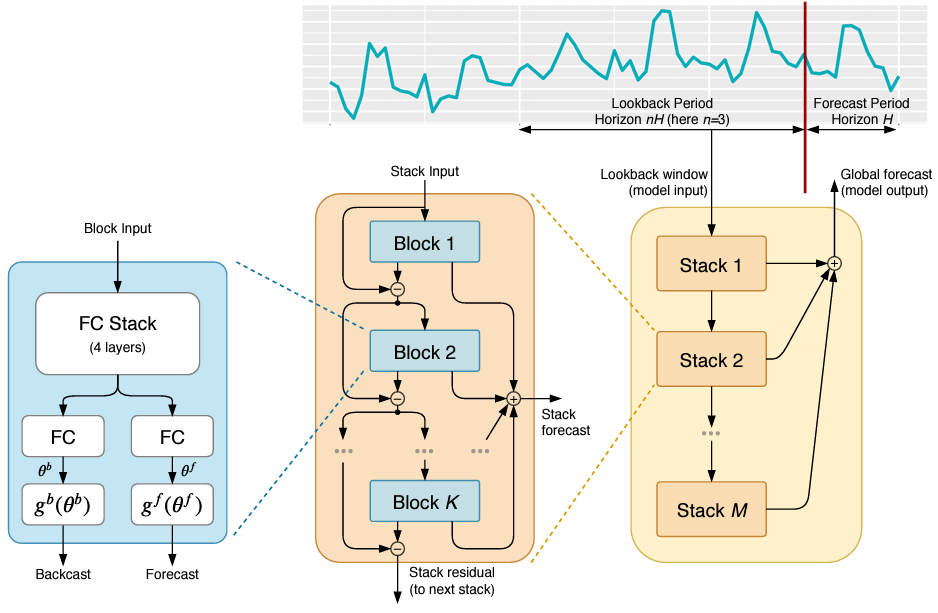

N-BEATS принимает в качестве гиперпараметров:
- Размеры входного и выходного слоев (константы INLEN и N_FC) должны быть достаточными, чтобы назначить узел каждому признаку в исходных данных. Длина входного куска не должна быть меньше порядка сезонности, иначе процессу обучения будет сложнее объединять куски. Для эффективного использования памяти установите как степень 2.
- Количество блоков в стеке (BLOCKS).
- Ширина каждого полностью связанного слоя в каждом блоке стека: количество его узлов (LWIDTH).
- Размер партии (batch size) определяет количество наблюдений, которые модель будет обрабатывать перед обновлением весов своей матрицы. Чтобы эффективно согласовать его со структурой памяти вашей системы, установите его равным степени числа 2. Очень большие размеры партии могут сбить градиентный спуск в одном направлении - модель может зайти в неоптимальный минимум. Меньшие размеры партии заставят градиентный спуск двигаться в разных направлениях, что может привести к снижению точности, но они также предотвращают перестройку модели. Наиболее часто рекомендуется выбирать начальный размер партии 32. Поскольку наш набор данных имеет частоту 24 часа, установим размер партии на следующий двоичный потолок, который может обработать 24 временных шага: 32.
- Эпохи (epochs) указывают модели, сколько циклов обучения она должна выполнить. В течение каждой эпохи модель будет обрабатывать весь обучающий набор, делая один прямой и один обратный проход.

Допуская некоторое упрощение, произведение этих гиперпараметров определяет тензорный размер модели. Большие значения параметров могут привести к ограничению памяти вашей системы и экспоненциальному увеличению времени обработки. В то время как малые значения параметров могут оказаться недостаточными для отражения сложных закономерностей в исходных данных.

Вероятностный прогноз будем строить с помощью квантильной регрессии. Этой опцией мы можем воспользоваться во всех моделях глубокого прогнозирования. Функция потерь нейронной сети может быть сформулирована как квантильная функция потерь.  

Пары квантилей, такие как 1%/99% или 10%/90%, выражают диапазон, в котором прогнозируемое значение может изменяться, выше или ниже центрального значения (с оговорками).

Небольшой пакет `missingno` является необязательным: missingno помогает визуализировать, как нулевые значения разбросаны по строкам и столбцам. Вы можете не устанавливать его и удалить соответствующую строку кода, что не повлияет на остальную часть сценария прогнозирования.

In [70]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
import missingno as mno

import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.CRITICAL)


from darts import TimeSeries, concatenate
from darts.dataprocessing.transformers import Scaler
from darts.models import NBEATSModel
from darts.metrics import mape, rmse
from darts.utils.timeseries_generation import datetime_attribute_timeseries
from darts.utils.likelihood_models import QuantileRegression


pd.set_option("display.precision",2)
np.set_printoptions(precision=2, suppress=True)
pd.options.display.float_format = '{:,.2f}'.format

### Настройки

В ячейке настроек блокнота перечислены гиперпараметры, которые будут управлять моделью N-BEATS.

В самом верху мы видим параметр `LOAD`. Если пользователь установит значение `True`, сценарий не будет (повторно) обучать модель, а загрузит в память ранее сохраненный tar-файл из текущего рабочего каталога. Сценарий приступит к созданию прогнозных значений на основе этой загруженной модели и пропустит трудоемкую сессию обучения. Параметр `LOAD` также полезен для переноса предварительно обученной модели на другую машину, например, на рабочий сервер.

Параметр `RAND` делает результаты воспроизводимыми.

`N_SAMPLES` советует модели брать N случайных значений прогноза на временном шаге, а не просто вычислять точечную оценку. Для вероятностного прогноза значение `N_SAMPLES` должно быть больше 1. Количество выборок не увеличивает существенно время обработки. Квантильная функция потерь генерирует выборки при низких вычислительных затратах.

`N-JOBS` ограничивает количество процессорных ядер, которые скрипт может задействовать параллельно. Если установить значение -1, все ядра будут доступны для модели.

Список `QUANTILES` информирует модель об уровнях, для которых она должна вычислить квантили прогноза.

`SPLIT` задает процентную долю фактических наблюдений, которая должна быть зарезервирована для обучения.

`FIGSIZE` рекомендует размер по умолчанию для графиков.

In [ ]:
LOAD = False         # True = загрузить ранее сохраненную модель с диска?  False = (повторное) обучение модели
# SAVE = "\_NBEATS_model_03.pth.tar"   # имя файла для сохранения модели

EPOCHS = 200
INLEN = 32          # input size
BLOCKS = 64         
LWIDTH = 32
BATCH = 64          # batch size
LEARN = 1e-3        # скорость обучения (learning rate)
VALWAIT = 1         # эпохи для ожидания перед оценкой потерь на тестовом/оценочном множестве
N_FC = 1            # output size

RAND = 42           # random seed
N_SAMPLES = 100     # количество раз, когда предсказание выбирается из вероятностной модели
N_JOBS = 3          # parallel processors to use;  -1 = all processors

# квантили для QuantileRegression
QUANTILES = [0.01, 0.1, 0.2, 0.5, 0.8, 0.9, 0.99]

SPLIT = 0.9         # train/test %

FIGSIZE = (9, 6)


qL1, qL2 = 0.01, 0.10        # процентили прогнозов: нижняя граница
qU1, qU2 = 1-qL1, 1-qL2,     # верхняя граница
label_q1 = f'{int(qU1 * 100)} / {int(qL1 * 100)} percentile band'
label_q2 = f'{int(qU2 * 100)} / {int(qL2 * 100)} percentile band'

# mpath = os.path.abspath(os.getcwd()) + SAVE     # путь и имя файла для сохранения модели

# Загрузка и подготовка данных

Набор данных доступен для загрузки с сайта Kaggle https://www.kaggle.com/nicholasjhana/energy-consumption-generation-prices-and-weather

Источник состоит из двух файлов csv:
- Энергетический файл содержит почасовые цены на электроэнергию в Испании, в евро за мегаватт-час (€/MWh); производство электроэнергии по типу происхождения (уголь, газ, энергия ветра и т.д.) в МВтч; и спрос на энергию ("нагрузка") в МВтч.
- В погодном файле представлены почасовые данные по пяти крупным испанским городам.

Мы ограничим наш анализ последним годом в данных наблюдений, 2018, и спрогнозируем почасовые цены на электроэнергию примерно для 870 временных шагов в конце года.

In [71]:
# load
df0 = pd.read_csv('data/energy_dataset.csv', header=0, parse_dates=["time"])
dfw0 = pd.read_csv('data/weather_features.csv', header=0, parse_dates=["dt_iso"])

In [72]:
df0.iloc[[0, -1]]

,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2015-01-01 00:00:00+01:00,447.00,329.00,0.00,"4,844.00","4,821.00",162.00,0.00,0.00,0.00,...,196.00,0.00,"6,378.00",17.00,nan,"6,436.00","26,118.00","25,385.00",50.10,65.41
35063,2018-12-31 23:00:00+01:00,290.00,0.00,0.00,"6,926.00","2,166.00",163.00,0.00,0.00,0.00,...,287.00,0.00,"3,651.00",26.00,nan,"3,117.00","24,424.00","24,455.00",64.27,69.88


In [73]:
dfw0.iloc[[0, -1]]

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-01 00:00:00+01:00,Valencia,270.48,270.48,270.48,1001,77,1,62,0.00,0.00,0.00,0,800,clear,sky is clear,01n
178395,2018-12-31 23:00:00+01:00,Seville,283.97,282.15,285.15,1029,70,3,50,0.00,0.00,0.00,0,800,clear,sky is clear,01n


In [74]:
# backup of original sources
df1 = df0.copy()
dfw1 = dfw0.copy()

## Подготовка данных

Большинство столбцов в наборе данных по энергетике сообщают о производстве электроэнергии в мегаватт-часах по типу источника, например, ветряные, угольные или солнечные электростанции.


In [75]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   time                                         35064 non-null  object 
 1   generation biomass                           35045 non-null  float64
 2   generation fossil brown coal/lignite         35046 non-null  float64
 3   generation fossil coal-derived gas           35046 non-null  float64
 4   generation fossil gas                        35046 non-null  float64
 5   generation fossil hard coal                  35046 non-null  float64
 6   generation fossil oil                        35045 non-null  float64
 7   generation fossil oil shale                  35046 non-null  float64
 8   generation fossil peat                       35046 non-null  float64
 9   generation geothermal                        35046 non-null  float64
 10

count of duplicates: 0
non-numeric columns: []
MISSING values:



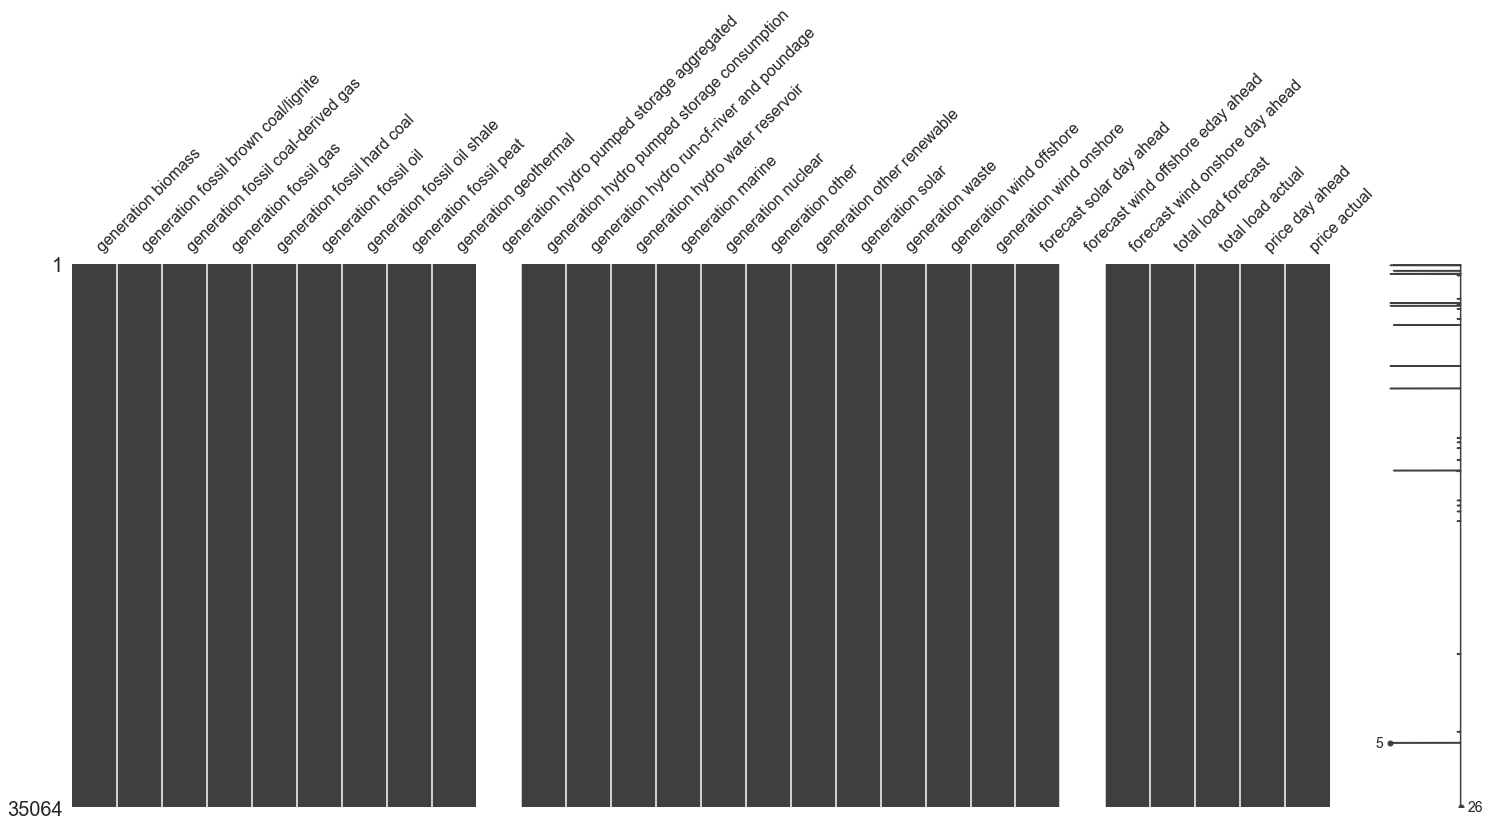

In [76]:
# datetime
df1["time"] = pd.to_datetime(df1["time"], utc=True, infer_datetime_format=True)

# any duplicate time periods?
print("count of duplicates:",df1.duplicated(subset=["time"], keep="first").sum())

df1.set_index("time", inplace=True)

# any non-numeric types?
print("non-numeric columns:",list(df1.dtypes[df1.dtypes == "object"].index))

# ищет пропуски, если находим их, вызывает функцию missingno
# для визуализации того, как они распределены по столбцам и строкам.
def gaps(df):
    if df.isnull().values.any():
        print("MISSING values:\n")
        mno.matrix(df)
    else:
        print("no missing values\n")
gaps(df1)  


In [77]:
# drop NaN и нулевые столбцы, а также 'forecast'
df1 = df1.drop(df1.filter(regex="forecast").columns, axis=1, errors="ignore")
df1.dropna(axis=1, how="all", inplace=True)
df1 = df1.loc[:, (df1!=0).any(axis=0)]

In [78]:
# заменить отсутствующие значения в строках оставшихся столбцов
# используя следующее достоверное наблюдение для заполнения
df1 = df1.interpolate(method ="bfill") 
# any missing values left?
gaps(df1)

df1 = df1.loc[:, (df1!=0).any(axis=0)]

no missing values



Оригинальные имена столбцов содержат некоторые пробелы и специальные символы. Давайте избавимся от них, переименовав столбцы.

In [79]:
# переименовать признаки
colnames_old = df1.columns
colnames_new = ["gen_bio", "gen_lig", "gen_gas", "gen_coal", \
                "gen_oil", "gen_hyd_pump", "gen_hyd_river", "gen_hyd_res", \
                "gen_nuc", "gen_other", "gen_oth_renew", "gen_solar", \
                "gen_waste", "gen_wind", "load_actual", "price_dayahead", \
                "price"]
dict_cols = dict(zip(colnames_old, colnames_new))
df1.rename(columns=dict_cols, inplace=True)
print(df1.info())
df1.describe()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 35064 entries, 2014-12-31 23:00:00+00:00 to 2018-12-31 22:00:00+00:00
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   gen_bio         35064 non-null  float64
 1   gen_lig         35064 non-null  float64
 2   gen_gas         35064 non-null  float64
 3   gen_coal        35064 non-null  float64
 4   gen_oil         35064 non-null  float64
 5   gen_hyd_pump    35064 non-null  float64
 6   gen_hyd_river   35064 non-null  float64
 7   gen_hyd_res     35064 non-null  float64
 8   gen_nuc         35064 non-null  float64
 9   gen_other       35064 non-null  float64
 10  gen_oth_renew   35064 non-null  float64
 11  gen_solar       35064 non-null  float64
 12  gen_waste       35064 non-null  float64
 13  gen_wind        35064 non-null  float64
 14  load_actual     35064 non-null  float64
 15  price_dayahead  35064 non-null  float64
 16  price           35064 non-nul

,gen_bio,gen_lig,gen_gas,gen_coal,gen_oil,gen_hyd_pump,gen_hyd_river,gen_hyd_res,gen_nuc,gen_other,gen_oth_renew,gen_solar,gen_waste,gen_wind,load_actual,price_dayahead,price
count,"35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00"
mean,383.53,448.10,"5,622.70","4,256.51",298.34,475.60,972.20,"2,605.57","6,263.47",60.23,85.63,"1,432.83",269.42,"5,464.85","28,698.95",49.87,57.88
std,85.35,354.62,"2,201.48","1,962.01",52.52,792.34,400.71,"1,835.35",840.30,20.24,14.08,"1,679.95",50.22,"3,213.47","4,576.56",14.62,14.20
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"18,041.00",2.06,9.33
25%,333.00,0.00,"4,126.00","2,527.00",263.00,0.00,637.00,"1,078.00","5,759.00",53.00,73.00,71.00,240.00,"2,933.00","24,807.75",41.49,49.35
50%,367.00,509.00,"4,969.00","4,475.00",300.00,68.00,906.00,"2,164.00","6,564.00",57.00,88.00,616.00,279.00,"4,849.50","28,904.00",50.52,58.02
75%,433.00,757.00,"6,429.00","5,839.00",330.00,616.00,"1,250.00","3,758.00","7,025.00",80.00,97.00,"2,579.00",310.00,"7,401.00","32,195.00",60.53,68.01
max,592.00,999.00,"20,034.00","8,359.00",449.00,"4,523.00","2,000.00","9,728.00","7,117.00",106.00,119.00,"5,792.00",357.00,"17,436.00","41,015.00",101.99,116.80


Попытка уменьшить разрядность данных с 64 до 32, но не вышло, Pytorch ругается

Вернулись к 64

In [80]:
# convert int and float64 columns to float32
intcols = list(df1.dtypes[df1.dtypes == np.int64].index)
df1[intcols] = df1[intcols].applymap(np.float64)

f64cols = list(df1.dtypes[df1.dtypes == np.float64].index)
df1[f64cols] = df1[f64cols].applymap(np.float64)

На ценовом графике изображена кривая с переодическими пиками и провалами. Их амплитуды различны, что подразумевает, что мы имеем дело с сезонностью более чем одного порядка. Уровень цен не демонстрирует устойчивой тенденции к росту или снижению. Он имеет тенденцию возвращаться к уровню около € 60/МВтч.

Временной ряд подвержен разным видам сезонностей:
+ часовая: влияют различные уровни использования электроэнергии в дневные и рабочие часы; производство солнечной энергии ограничено дневными часами
+ ежедневная: потребление электроэнергии будет выше в рабочие дни, чем в выходные
+ месячная: сезонные колебания спроса, вызванные разницей температур; и сезонные колебания мощности солнечных и ветряных источников энергии
энергии

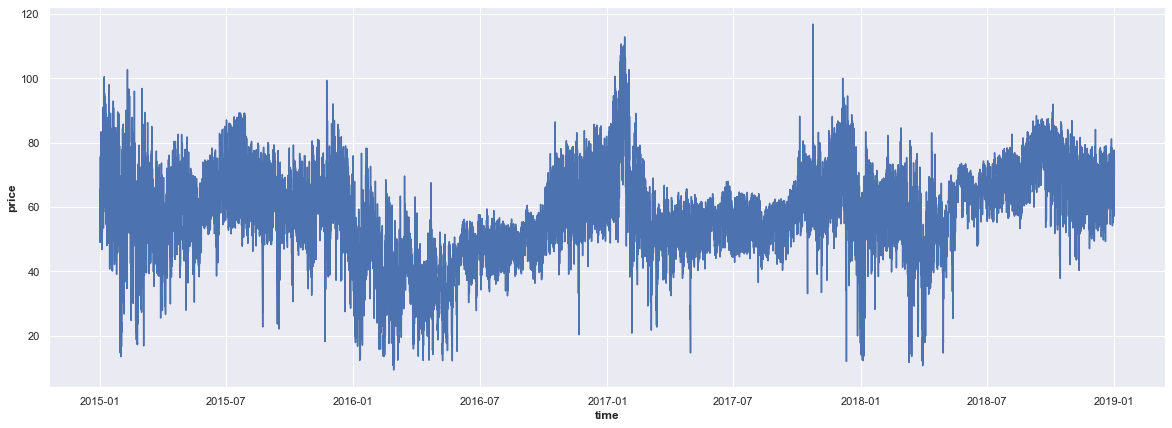

In [81]:
plt.figure(100, figsize=(20, 7))
sns.lineplot(x = "time", y = "price", data = df1, palette="coolwarm");

## Подготовка данных для dfw1

Набор погодных данных включает в себя пять испанских мегаполисов и их почасовые записи погоды.
Мы объединим данные об энергии и данные о погоде в единый массив данных.

Данные о погоде состоят из 17 столбцов. Функция info() сообщает нам, что недостающие значения обрабатывать не нужно.

In [82]:
dfw1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178396 entries, 0 to 178395
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   dt_iso               178396 non-null  object 
 1   city_name            178396 non-null  object 
 2   temp                 178396 non-null  float64
 3   temp_min             178396 non-null  float64
 4   temp_max             178396 non-null  float64
 5   pressure             178396 non-null  int64  
 6   humidity             178396 non-null  int64  
 7   wind_speed           178396 non-null  int64  
 8   wind_deg             178396 non-null  int64  
 9   rain_1h              178396 non-null  float64
 10  rain_3h              178396 non-null  float64
 11  snow_3h              178396 non-null  float64
 12  clouds_all           178396 non-null  int64  
 13  weather_id           178396 non-null  int64  
 14  weather_main         178396 non-null  object 
 15  weather_descripti

In [83]:
# datetime
dfw1["time"] = pd.to_datetime(dfw1["dt_iso"], utc=True, infer_datetime_format=True)
dfw1.set_index("time", inplace=True)

# any non-numeric types?
print("non-numeric columns:",list(dfw1.dtypes[dfw1.dtypes == "object"].index))

# any missing values?
def gaps(df):
    if df.isnull().values.any():
        print("MISSING values:\n")
        mno.matrix(df)
    else:
        print("no missing values\n")  
gaps(dfw1) 


dfw1.describe()

non-numeric columns: ['dt_iso', 'city_name', 'weather_main', 'weather_description', 'weather_icon']
no missing values



,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id
count,"178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00"
mean,289.62,288.33,291.09,"1,069.26",68.42,2.47,166.59,0.08,0.00,0.00,25.07,759.83
std,8.03,7.96,8.61,"5,969.63",21.90,2.10,116.61,0.40,0.01,0.22,30.77,108.73
min,262.24,262.24,262.24,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,200.00
25%,283.67,282.48,284.65,"1,013.00",53.00,1.00,55.00,0.00,0.00,0.00,0.00,800.00
50%,289.15,288.15,290.15,"1,018.00",72.00,2.00,177.00,0.00,0.00,0.00,20.00,800.00
75%,295.15,293.73,297.15,"1,022.00",87.00,4.00,270.00,0.00,0.00,0.00,40.00,801.00
max,315.60,315.15,321.15,"1,008,371.00",100.00,133.00,360.00,12.00,2.31,21.50,100.00,804.00


Описательная статистика показывает некоторые значения, которые, очевидно, являются выбросами. Атмосферное давление не может подняться выше миллиона миллибар. В Испании в этом веке не было зафиксировано такой скорости ветра, как 133 км/ч. Столбцы температуры выглядят диковинно, с показателями выше 300 градусов. Но эти значения просто выражены в кельвинах и поэтому не предполагают явных выбросов.

Далее мы убираем некоторые неактуальные или избыточные столбцы - те, которые представляют собой словесное резюме количественных столбцов; и дождь, измеренный за последние 3 часа, который является избыточным, так как мы также измеряем дождь за последний час.

In [84]:
# drop unnecessary columns
dfw1.drop(["rain_3h", "weather_id", "weather_main", "weather_description", "weather_icon"], 
          inplace=True, axis=1, errors="ignore")


# конвертируем кельвины в градусы Цельсия.
temp_cols = [col for col in dfw1.columns if "temp" in col]
dfw1[temp_cols] = dfw1[temp_cols].filter(like="temp").applymap(lambda t: t - 273.15)


In [85]:
# convert int and float64 columns to float32
intcols = list(dfw1.dtypes[dfw1.dtypes == np.int64].index)
dfw1[intcols] = dfw1[intcols].applymap(np.float64)

f64cols = list(dfw1.dtypes[dfw1.dtypes == np.float64].index)
dfw1[f64cols] = dfw1[f64cols].applymap(np.float64)

f32cols = list(dfw1.dtypes[dfw1.dtypes == np.float64].index)
dfw1.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 178396 entries, 2014-12-31 23:00:00+00:00 to 2018-12-31 22:00:00+00:00
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   dt_iso      178396 non-null  object 
 1   city_name   178396 non-null  object 
 2   temp        178396 non-null  float64
 3   temp_min    178396 non-null  float64
 4   temp_max    178396 non-null  float64
 5   pressure    178396 non-null  float64
 6   humidity    178396 non-null  float64
 7   wind_speed  178396 non-null  float64
 8   wind_deg    178396 non-null  float64
 9   rain_1h     178396 non-null  float64
 10  snow_3h     178396 non-null  float64
 11  clouds_all  178396 non-null  float64
dtypes: float64(10), object(2)
memory usage: 17.7+ MB


In [86]:
# посмотрим на выбросы в данных о давлении
dfw1["pressure"].nlargest(10)

time
2015-02-21 01:00:00+00:00   1,008,371.00
2015-02-22 07:00:00+00:00   1,002,881.00
2015-02-22 06:00:00+00:00   1,002,241.00
2015-02-21 08:00:00+00:00   1,001,781.00
2015-02-21 09:00:00+00:00   1,001,501.00
2015-02-21 10:00:00+00:00   1,000,951.00
2015-02-20 08:00:00+00:00     102,153.00
2015-02-20 09:00:00+00:00     102,132.00
2015-02-20 10:00:00+00:00     102,075.00
2015-02-20 11:00:00+00:00     101,983.00
Name: pressure, dtype: float64

In [87]:
# посмотрим на выбросы в данных о скорости ветра
dfw1["wind_speed"].nlargest(10)

time
2017-05-11 10:00:00+00:00   133.00
2015-01-30 10:00:00+00:00    64.00
2015-01-30 14:00:00+00:00    54.00
2015-02-23 21:00:00+00:00    43.00
2015-01-30 15:00:00+00:00    40.00
2015-01-30 18:00:00+00:00    38.00
2015-01-30 02:00:00+00:00    35.00
2015-01-30 09:00:00+00:00    33.00
2015-01-16 12:00:00+00:00    30.00
2015-01-29 13:00:00+00:00    30.00
Name: wind_speed, dtype: float64

Среди скоростей ветра есть один явный выброс - 11 мая 2017 года.

Еще раз посмотрим на выбросы, но уже с помощью Boxplot

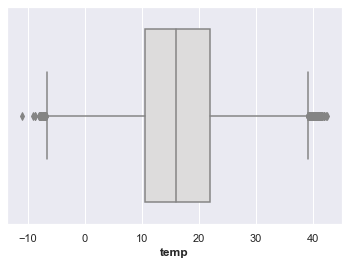

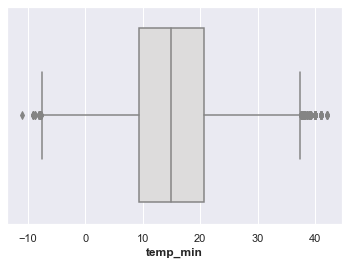

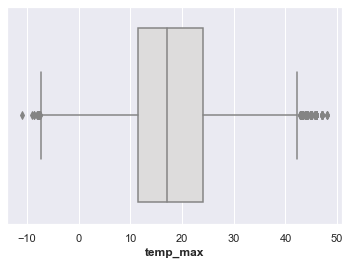

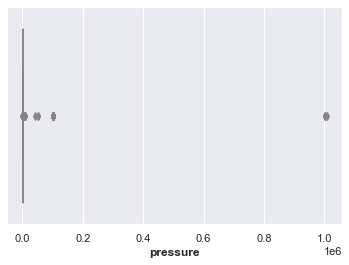

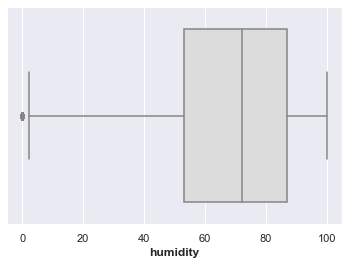

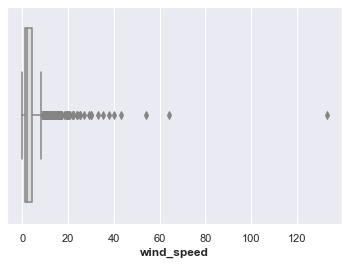

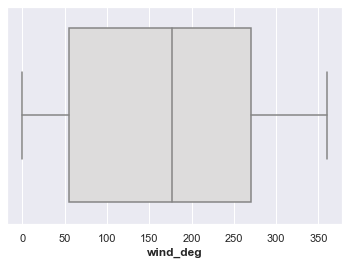

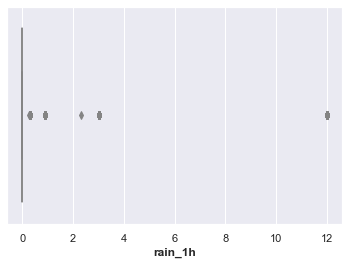

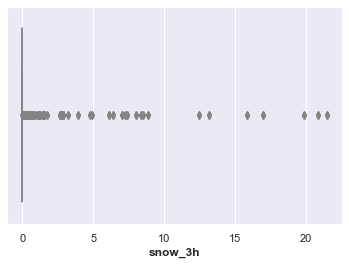

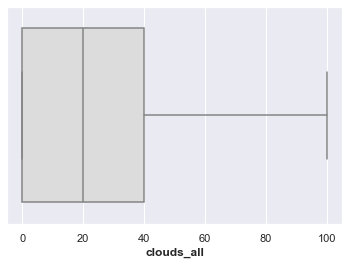

In [88]:
# boxplots
for i, c in enumerate(f32cols):
    sns.boxplot(x=dfw1[c], palette="coolwarm")
    plt.show();

Влажность и температура соответствуют норме. Влажность, равная нулю, в крайнем левом углу, вероятно, является ошибкой измерения. Можно рассмотреть возможность замены нулевых значений путем обратного или прямого заполнения их соседними ненулевыми значениями. Но в данном случае оставим их без изменений.

Графики для давления и скорости ветра, однако, выделяют несколько серьезных выбросов направом конце шкалы.

В качестве альтернативы можно использовать distplots, чтобы выявить выбросы.
Температурная кривая показывает нормальный сезонный цикл - то зимнего холода до летнего зноя. Без сравнения со сторонними данными мы не обнаружим явных выбросов в умеренном поясе
.
Но экстремальный эксцесс и перекос распределений давления и скорости ветра указывают на наличие выбросов в их правых хвостах.

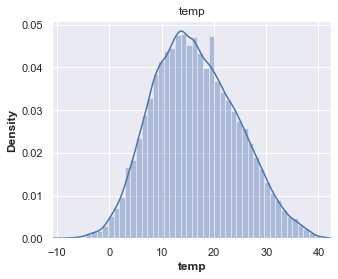

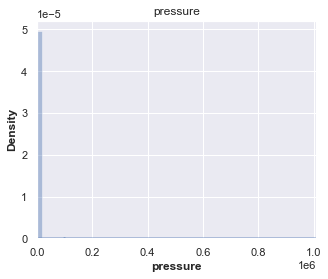

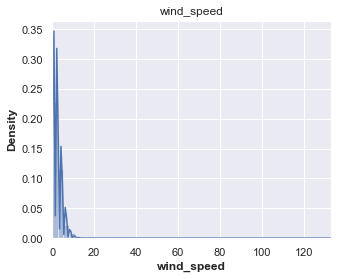

In [89]:
fig = plt.figure(figsize=(5, 4)) 
ax = sns.distplot(dfw1["temp"])
xmin = dfw1["temp"].min()
xmax = dfw1["temp"].max()  
ax.set_xlim(xmin, xmax)
ax.set_title("temp");

fig = plt.figure(figsize=(5, 4))
ax = sns.distplot(dfw1["pressure"])
xmin = dfw1["pressure"].min()
xmax = dfw1["pressure"].max()  
ax.set_xlim(xmin, xmax)
ax.set_title("pressure");

fig = plt.figure(figsize=(5, 4))
ax = sns.distplot(dfw1["wind_speed"])
xmin = dfw1["wind_speed"].min()
xmax = dfw1["wind_speed"].max()  
ax.set_xlim(xmin, xmax)
ax.set_title("wind_speed");

Заменим выбросы, превышающие выбранный порог, на значение `null`. Затем заполним вновь образовавшиеся пробелы с помощью обратной интерполяции.

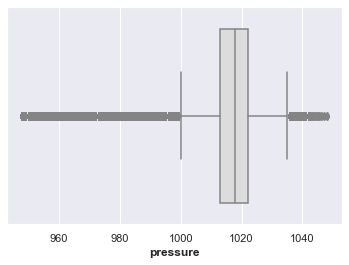

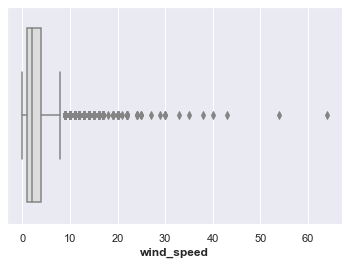

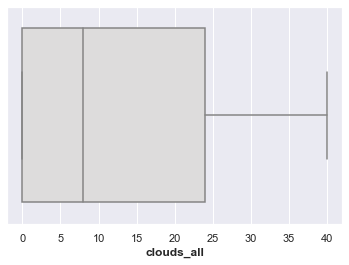

,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,snow_3h,clouds_all
count,"178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00","178,396.00"
mean,16.47,15.18,17.94,"1,016.16",68.42,2.47,166.59,0.08,0.00,14.59
std,8.03,7.96,8.61,11.68,21.90,2.07,116.61,0.40,0.22,16.04
min,-10.91,-10.91,-10.91,948.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,10.52,9.33,11.50,"1,013.00",53.00,1.00,55.00,0.00,0.00,0.00
50%,16.00,15.00,17.00,"1,018.00",72.00,2.00,177.00,0.00,0.00,8.00
75%,22.00,20.58,24.00,"1,022.00",87.00,4.00,270.00,0.00,0.00,24.00
max,42.45,42.00,48.00,"1,048.00",100.00,64.00,360.00,12.00,21.50,40.00


In [90]:
# treatment of outliers: replace with NaN, then interpolate
dfw1["pressure"].where( dfw1["pressure"] <= 1050, inplace=True)
dfw1["pressure"].where( dfw1["pressure"] >= 948, inplace=True)
dfw1["wind_speed"].where( dfw1["wind_speed"] <= 120, inplace=True)
dfw1["clouds_all"].where( dfw1["clouds_all"] <= 40, inplace=True)
dfw1 = dfw1.interpolate(method ="bfill")

sns.boxplot(x=dfw1["pressure"], palette="coolwarm")
plt.show();
sns.boxplot(x=dfw1["wind_speed"], palette="coolwarm")
plt.show();
sns.boxplot(x=dfw1["clouds_all"], palette="coolwarm")
plt.show();

dfw1.describe()

Посмотрим имеют ли совместимые индексы времени ВР энергии и погоды.

In [91]:
# start and end of energy and weather time series 
print("earliest weather time period:", dfw1.index.min())
print("latest weather time period:", dfw1.index.max())

print("earliest energy time period:", df1.index.min())
print("latest energy time period:", df1.index.max())

earliest weather time period: 2014-12-31 23:00:00+00:00
latest weather time period: 2018-12-31 22:00:00+00:00
earliest energy time period: 2014-12-31 23:00:00+00:00
latest energy time period: 2018-12-31 22:00:00+00:00


Имеющиеся погодные данные были получены для пяти крупных испанских городов.

In [92]:
# cities in weather data
cities = dfw1["city_name"].unique()
cities

array(['Valencia', 'Madrid', 'Bilbao', ' Barcelona', 'Seville'],
      dtype=object)

Когда мы проверим записи о погоде на наличие дублирующихся пар городов и индексов времени, мы обнаружим 3 076 таких пар. Удалим их.

Если сгруппировать данные о погоде по городам, то получим 35 064 записи о погоде для каждого города, что совпадает с количеством записей в наборе данных по энергетике.

In [93]:
# drop duplicate time periods
print("count of duplicates before treatment:",dfw1.duplicated(subset=["dt_iso", "city_name"], keep="first").sum())

dfw1 = dfw1.drop_duplicates(subset=["dt_iso", "city_name"], keep="first")
dfw1.reset_index()
print("count of duplicates after treatment:",dfw1.duplicated(subset=["dt_iso", "city_name"], keep="first").sum())

# set datetime index
dfw1["time"] = pd.to_datetime(dfw1["dt_iso"], utc=True, infer_datetime_format=True)
dfw1.set_index("time", inplace=True)
dfw1.drop("dt_iso", inplace=True, axis=1)


print("size of energy dataframe:", df1.shape[0])
dfw1_city = dfw1.groupby("city_name").count()
dfw1_city

count of duplicates before treatment: 3076
count of duplicates after treatment: 0
size of energy dataframe: 35064


,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,snow_3h,clouds_all
city_name,,,,,,,,,,
Barcelona,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064
Bilbao,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064
Madrid,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064
Seville,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064
Valencia,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064


Мы выделяем записи о погоде каждого города в отдельный фрейм данных, чтобы подготовиться к слиянию записей об энергии и погоде.

Названия городов служат ключами словаря. Выбрав, например, ключ "Bilbao", мы можем получить из словаря фрейм данных для этого города.

In [94]:
# count of weather observations by city
print("size of energy dataframe:", df1.shape[0])

dfw1["city_name"] = dfw1["city_name"].replace(" Barcelona", "Barcelona")   # remove space in name
dfw1_city = dfw1.groupby("city_name")
print("size of city groups in weather dataframe:")
dfw1_city.count()

size of energy dataframe: 35064
size of city groups in weather dataframe:


,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,snow_3h,clouds_all
city_name,,,,,,,,,,
Barcelona,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064
Bilbao,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064
Madrid,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064
Seville,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064
Valencia,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064


In [95]:
# separate the cities: a weather dataframe for each of them
dict_city_weather = {city:df_city for city,df_city in dfw1_city}
dict_city_weather.keys()

dict_keys(['Barcelona', 'Bilbao', 'Madrid', 'Seville', 'Valencia'])

In [96]:
# example: Bilbao weather dataframe
dfw_Bilbao = dict_city_weather.get("Bilbao")
print("Bilbao weather:")
dfw_Bilbao.describe()

Bilbao weather:


,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,snow_3h,clouds_all
count,"35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00","35,064.00"
mean,13.29,11.84,14.94,"1,017.48",78.73,1.96,159.91,0.12,0.02,22.97
std,6.80,6.82,6.99,9.82,16.71,1.87,122.86,0.37,0.50,16.66
min,-6.30,-9.00,-4.17,961.00,11.00,0.00,0.00,0.00,0.00,0.00
25%,8.30,7.00,10.00,"1,013.00",67.00,1.00,31.00,0.00,0.00,0.00
50%,13.02,11.70,15.00,"1,019.00",82.00,1.00,150.00,0.00,0.00,20.00
75%,17.89,17.00,19.36,"1,024.00",93.00,3.00,290.00,0.00,0.00,40.00
max,39.32,38.89,45.56,"1,042.00",100.00,15.00,360.00,3.00,21.50,40.00


In [97]:
dfw_Bilbao.iloc[[0,-1]]

,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,snow_3h,clouds_all
time,,,,,,,,,,,
2014-12-31 23:00:00+00:00,Bilbao,-3.49,-3.49,-3.49,"1,036.00",97.00,0.00,226.00,0.00,0.00,0.00
2018-12-31 22:00:00+00:00,Bilbao,2.45,2.00,3.00,"1,034.00",93.00,2.00,100.00,0.00,0.00,0.00


### Слияние энергетических и погодных данных


In [98]:
# merge the energy and weather dataframes
df2 = df1.copy()
for city,df in dict_city_weather.items():
    city_name = str(city) + "_"
    df = df.add_suffix("_{}".format(city))
    df2 = pd.concat([df2, df], axis=1)
    df2.drop("city_name_" + city, inplace=True, axis=1)
print(df2.info())
df2.iloc[[0,-1]]

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 35064 entries, 2014-12-31 23:00:00+00:00 to 2018-12-31 22:00:00+00:00
Data columns (total 67 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   gen_bio               35064 non-null  float64
 1   gen_lig               35064 non-null  float64
 2   gen_gas               35064 non-null  float64
 3   gen_coal              35064 non-null  float64
 4   gen_oil               35064 non-null  float64
 5   gen_hyd_pump          35064 non-null  float64
 6   gen_hyd_river         35064 non-null  float64
 7   gen_hyd_res           35064 non-null  float64
 8   gen_nuc               35064 non-null  float64
 9   gen_other             35064 non-null  float64
 10  gen_oth_renew         35064 non-null  float64
 11  gen_solar             35064 non-null  float64
 12  gen_waste             35064 non-null  float64
 13  gen_wind              35064 non-null  float64
 14  load_actual           3

,gen_bio,gen_lig,gen_gas,gen_coal,gen_oil,gen_hyd_pump,gen_hyd_river,gen_hyd_res,gen_nuc,gen_other,...,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,snow_3h_Valencia,clouds_all_Valencia
time,,,,,,,,,,,,,,,,,,,,,
2014-12-31 23:00:00+00:00,447.00,329.00,"4,844.00","4,821.00",162.00,863.00,"1,051.00","1,899.00","7,096.00",43.00,...,-2.67,-2.67,-2.67,"1,001.00",77.00,1.00,62.00,0.00,0.00,0.00
2018-12-31 22:00:00+00:00,290.00,0.00,"6,926.00","2,166.00",163.00,108.00,"1,069.00","1,686.00","6,075.00",61.00,...,5.99,5.00,7.00,"1,029.00",75.00,2.00,300.00,0.00,0.00,0.00


Полученный набор данных df2 содержит 67 столбцов. Пропущенных значений и дубликатов нет.

In [99]:
# any null values?
print("any missing values?", df2.isnull().values.any())

# any ducplicate time periods?
print("count of duplicates:", df2.duplicated(keep="first").sum())

any missing values? False
count of duplicates: 0


## Исследование объединенного набора данных

При прогнозировании мы хотим получить цены на электроэнергию на ближайшие несколько часов. Сомнительно, что исторические цены или любая из переменных характеристик сформировали закономерности, которые сохранялись в течение нескольких лет и повлияют на цены, которые мы будем наблюдать через 12 часов. Поэтому ограничим исходные данные 8 760 часами последнего года, с января по декабрь 2018 года. В противном случае время на обучение было бы многократно увеличено.

In [100]:
# limit the dataframe's date range
df2 = df2[df2.index >= "2018-01-01 00:00:00+00:00"]
df2.iloc[[0,-1]]

,gen_bio,gen_lig,gen_gas,gen_coal,gen_oil,gen_hyd_pump,gen_hyd_river,gen_hyd_res,gen_nuc,gen_other,...,temp_Valencia,temp_min_Valencia,temp_max_Valencia,pressure_Valencia,humidity_Valencia,wind_speed_Valencia,wind_deg_Valencia,rain_1h_Valencia,snow_3h_Valencia,clouds_all_Valencia
time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00+00:00,275.00,0.00,"3,269.00",959.00,191.00,"2,115.00","1,046.00",799.00,"7,057.00",51.00,...,14.00,14.00,14.00,"1,026.00",44.00,5.00,270.00,0.00,0.00,0.00
2018-12-31 22:00:00+00:00,290.00,0.00,"6,926.00","2,166.00",163.00,108.00,"1,069.00","1,686.00","6,075.00",61.00,...,5.99,5.00,7.00,"1,029.00",75.00,2.00,300.00,0.00,0.00,0.00


### Корреляция признаков с ценой

Чтобы отсеять нерелевантные признакии среди 67 столбцов, мы рассчитаем их корреляцию с ценами.

In [101]:
# корреляции признаков и цены
df_corr = df2.corr(method="pearson")
print(df_corr.shape)
print("correlation with price:")
df_corrP = pd.DataFrame(df_corr["price"].sort_values(ascending=False))
df_corrP

(67, 67)
correlation with price:


,price
price,1.00
price_dayahead,0.67
gen_gas,0.49
gen_coal,0.46
temp_max_Seville,0.42
...,...
snow_3h_Barcelona,nan
snow_3h_Bilbao,nan
snow_3h_Madrid,nan
snow_3h_Seville,nan


Оставим только те признаки, которые имеют корреляцию больше 0.25.

In [102]:
# самые высокие абсолютные корреляции с ценой
pd.options.display.float_format = '{:,.2f}'.format
df_corrH = df_corrP[np.abs(df_corrP["price"]) > 0.25]
df_corrH

,price
price,1.00
price_dayahead,0.67
gen_gas,0.49
gen_coal,0.46
temp_max_Seville,0.42
load_actual,0.41
temp_Seville,0.41
temp_min_Seville,0.41
temp_max_Madrid,0.40
temp_Madrid,0.39


Мы получаем список из 28 признаков, которые имеют умеренную или высокую корреляцию с ценой на электроэнергию. Большинство из них состоит из температуры в городах, которые сильно коррелируют друг с другом. Очевидно, что между этими признаками существует довольно много избыточности, что подчеркивает корреляционная матрица, отображая глубокий красный прямоугольник температурных ячеек.

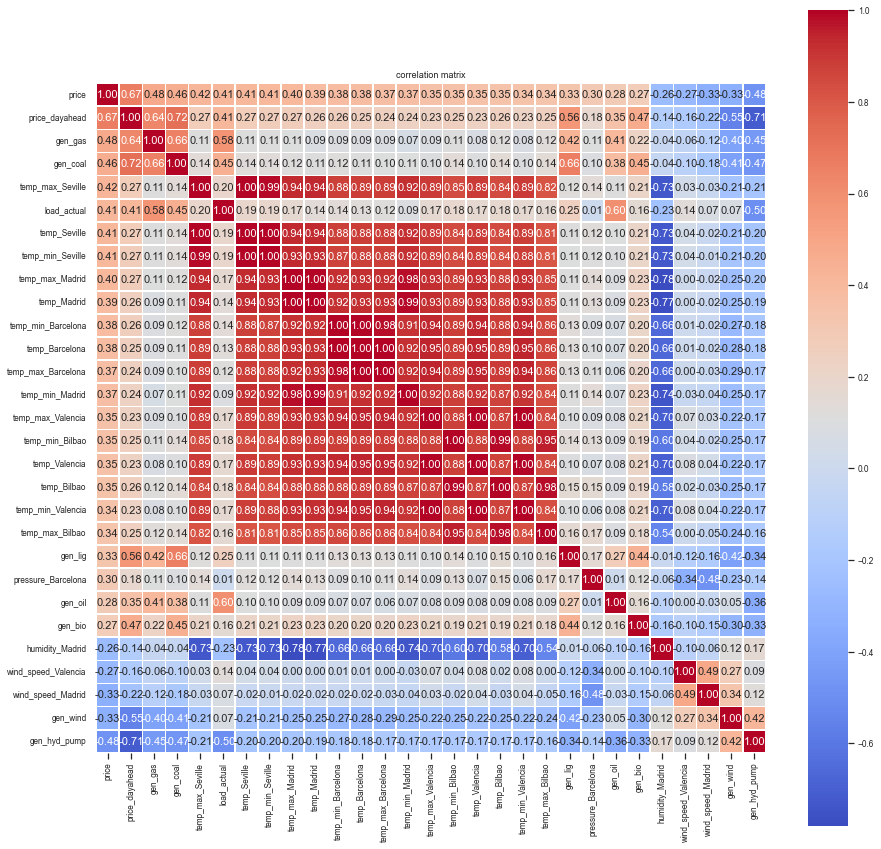

In [103]:
# correlation matrix, limited to highly correlated features
df3 = df2[df_corrH.index]

idx = df3.corr().sort_values("price", ascending=False).index
df3_sorted = df3.loc[:, idx]  # sort dataframe columns by their correlation with Appliances

plt.figure(figsize = (15,15))
sns.set(font_scale=0.75)
ax = sns.heatmap(df3_sorted.corr().round(3), 
            annot=True, 
            square=True, 
            linewidths=.75, cmap="coolwarm", 
            fmt = ".2f", 
            annot_kws = {"size": 11})
ax.xaxis.tick_bottom()
plt.title("correlation matrix")
plt.show()

Мы можем выбрать один из двух подходов.

В первом случае мы используем те 28 исходных признаков, которые хотя бы умеренно коррелируют с ценами. Альтернативой может быть анализ главных компонент, который сокращает 66 признаков до, надеюсь, нескольких их линейных комбинаций.

In [104]:
# оставим только те признаки, у которых есть корреляция с ценой (>0.25)
df3 = df2[df_corrH.index]
df3.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8759 entries, 2018-01-01 00:00:00+00:00 to 2018-12-31 22:00:00+00:00
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   price                8759 non-null   float64
 1   price_dayahead       8759 non-null   float64
 2   gen_gas              8759 non-null   float64
 3   gen_coal             8759 non-null   float64
 4   temp_max_Seville     8759 non-null   float64
 5   load_actual          8759 non-null   float64
 6   temp_Seville         8759 non-null   float64
 7   temp_min_Seville     8759 non-null   float64
 8   temp_max_Madrid      8759 non-null   float64
 9   temp_Madrid          8759 non-null   float64
 10  temp_min_Barcelona   8759 non-null   float64
 11  temp_Barcelona       8759 non-null   float64
 12  temp_max_Barcelona   8759 non-null   float64
 13  temp_min_Madrid      8759 non-null   float64
 14  temp_max_Valencia    8759 non-null   flo

### Календарные признаки

Далее исследуем сезонность временного ряда.

Когда мы группируем цены по месяцам и дням недели, полученная таблица в сочетании с тепловой картой визуализирует две закономерности: разницу в уровне цен в разные дни недели и сезонные колебания от месяца к месяцу. Мы наблюдаем разницу между рабочими и выходными днями, когда спрос на электроэнергию ниже, и видим самые высокие цены в конце летних месяцев.

Мы посмотрим на тепловые карты, которые не являются удобным способом анализа сезонности, но иногда применяются.

In [105]:
# additional datetime columns: feature engineering
df3["month"] = df3.index.month

df3["wday"] = df3.index.dayofweek
dict_days = {0:"1_Mon", 1:"2_Tue", 2:"3_Wed", 3:"4_Thu", 4:"5_Fri", 5:"6_Sat", 6:"7_Sun"}
df3["weekday"] = df3["wday"].apply(lambda x: dict_days[x])

df3["hour"] = df3.index.hour

df3 = df3.astype({"hour":float, "wday":float, "month": float})

df3.iloc[[0, -1]]

,price,price_dayahead,gen_gas,gen_coal,temp_max_Seville,load_actual,temp_Seville,temp_min_Seville,temp_max_Madrid,temp_Madrid,...,gen_bio,humidity_Madrid,wind_speed_Valencia,wind_speed_Madrid,gen_wind,gen_hyd_pump,month,wday,weekday,hour
time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00+00:00,19.02,4.74,"3,269.00",959.00,11.00,"22,009.00",10.39,10.00,7.00,6.43,...,275.00,65.00,5.00,4.00,"11,156.00","2,115.00",1.00,0.00,1_Mon,0.00
2018-12-31 22:00:00+00:00,69.88,64.27,"6,926.00","2,166.00",12.00,"24,455.00",10.82,9.00,2.00,2.00,...,290.00,74.00,2.00,1.00,"3,651.00",108.00,12.00,0.00,1_Mon,22.00


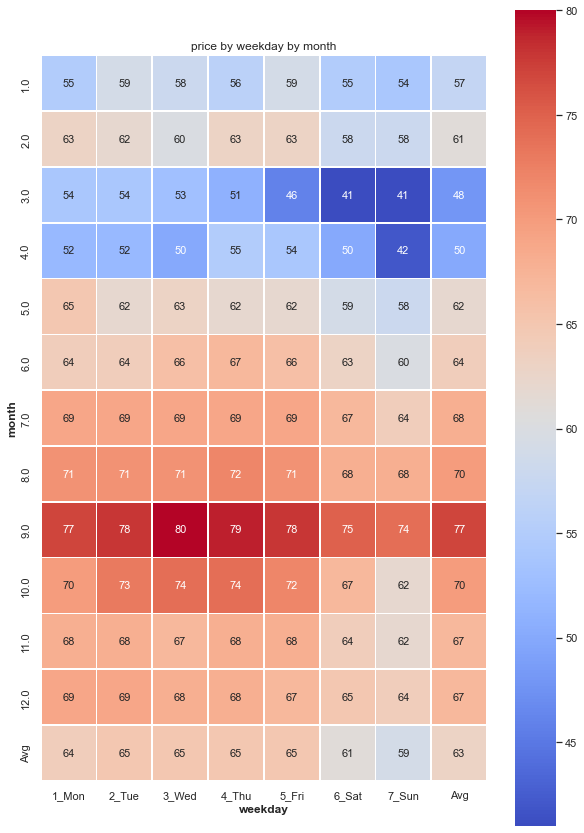

In [106]:
# pivot table: weekdays in months
piv = pd.pivot_table(   df3, 
                        values="price", 
                        index="month", 
                        columns="weekday", 
                        aggfunc="mean", 
                        margins=True, margins_name="Avg", 
                        fill_value=0)
pd.options.display.float_format = '{:,.0f}'.format

plt.figure(figsize = (10,15))
sns.set(font_scale=1)
sns.heatmap(piv.round(0), annot=True, square = True, \
            linewidths=.75, cmap="coolwarm", fmt = ".0f", annot_kws = {"size": 11})
plt.title("price by weekday by month")
plt.show()

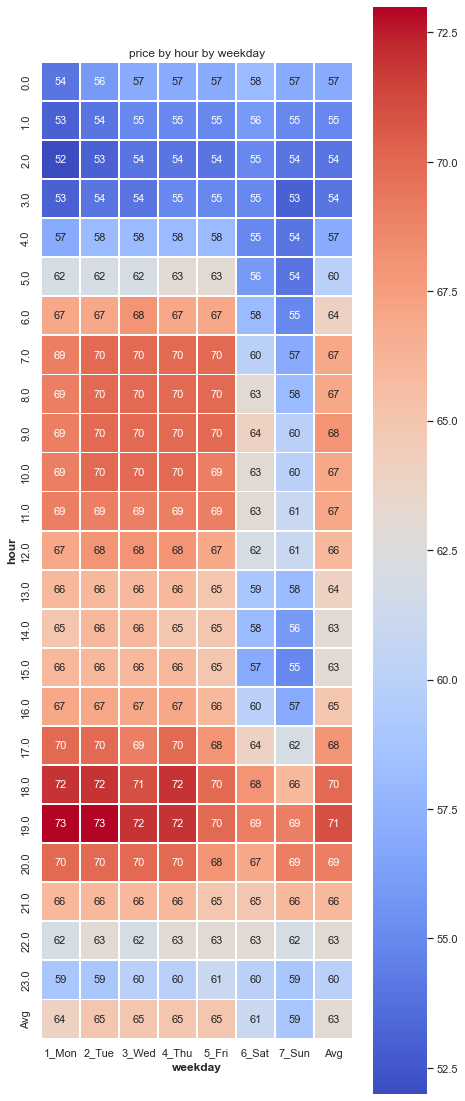

In [107]:
# pivot table: hours in weekdays
piv = pd.pivot_table(   df3, 
                        values="price", 
                        index="hour", 
                        columns="weekday", 
                        aggfunc="mean", 
                        margins=True, margins_name="Avg", 
                        fill_value=0)
pd.options.display.float_format = '{:,.0f}'.format

plt.figure(figsize = (7,20))
sns.set(font_scale=1)
sns.heatmap(piv.round(0), annot=True, square = True, \
            linewidths=.75, cmap="coolwarm", fmt = ".0f", annot_kws = {"size": 11})
plt.title("price by hour by weekday")
plt.show()

Вторая тепловая карта показывает разброс цен между дневными и ночными часами. Ранние дневные часы, вероятно, указывают на традиционную испанскую сиесту, во время которой интенсивность деловой активности снижается. Спрос на электроэнергию возобновляется в конце дня, а также резко возрастает во время, вероятно, обеденного перерыва.

In [108]:
# dataframe with price and features only
df4 = df3.copy()
df4.drop(["weekday", "month", "wday", "hour"], inplace=True, axis=1)

Мы пришли к выводу, что модель N-BEATS должна изучить три сезонные закономерности:
- почасовые колебания цен
- рабочие дни по сравнению с выходными
- холодные и теплые месяцы

# Объект временного ряда в DARTS

Darts оперирует объектами временных рядов, в которые нам нужно перевести серии `pandas` (или массивы `numpy`), содержащие исходные данные.
Сначала мы создадим одномерный целевой временной ряд `ts_P` из столбца `price` нашего датафрейма.


In [109]:
# create time series object for target variable
ts_P = TimeSeries.from_series(df4["price"]) 

# check attributes of the time series
print("components:", ts_P.components)
print("duration:",ts_P.duration)
print("frequency:",ts_P.freq)
print("frequency:",ts_P.freq_str)
print("has date time index? (or else, it must have an integer index):",ts_P.has_datetime_index)
print("deterministic:",ts_P.is_deterministic)
print("univariate:",ts_P.is_univariate)

components: Index(['price'], dtype='object', name='component')
duration: 364 days 22:00:00
frequency: <Hour>
frequency: H
has date time index? (or else, it must have an integer index): True
deterministic: True
univariate: True


Затем мы группируем столбцы признаков датафрейма в многомерный временной ряд ковариатов: `ts_covF`.

In [110]:
# create time series object for the feature columns
df_covF = df4.loc[:, df4.columns != "price"]
ts_covF = TimeSeries.from_dataframe(df_covF)

# check attributes of the time series
print("components (columns) of feature time series:", ts_covF.components)
print("duration:",ts_covF.duration)
print("frequency:",ts_covF.freq)
print("frequency:",ts_covF.freq_str)
print("has date time index? (or else, it must have an integer index):",ts_covF.has_datetime_index)
print("deterministic:",ts_covF.is_deterministic)
print("univariate:",ts_covF.is_univariate)


components (columns) of feature time series: Index(['price_dayahead', 'gen_gas', 'gen_coal', 'temp_max_Seville',
       'load_actual', 'temp_Seville', 'temp_min_Seville', 'temp_max_Madrid',
       'temp_Madrid', 'temp_min_Barcelona', 'temp_Barcelona',
       'temp_max_Barcelona', 'temp_min_Madrid', 'temp_max_Valencia',
       'temp_min_Bilbao', 'temp_Valencia', 'temp_Bilbao', 'temp_min_Valencia',
       'temp_max_Bilbao', 'gen_lig', 'pressure_Barcelona', 'gen_oil',
       'gen_bio', 'humidity_Madrid', 'wind_speed_Valencia',
       'wind_speed_Madrid', 'gen_wind', 'gen_hyd_pump'],
      dtype='object', name='component')
duration: 364 days 22:00:00
frequency: <Hour>
frequency: H
has date time index? (or else, it must have an integer index): True
deterministic: True
univariate: False


При необходимости объекты временных рядов Darts могут быть преобразованы обратно в массивы numpy, pandas.

In [111]:
# пример: работа с объектами временного ряда:
# мы также можем создать 3-мерный массив numpy из объекта временного ряда
# 3 dimensions: time (rows) / components (columns) / samples
ar_covF = ts_covF.all_values()
print(type(ar_covF))
ar_covF.shape

<class 'numpy.ndarray'>


(8759, 28, 1)

In [112]:
# пример: работа с объектами временного ряда:
# мы также можем создать серию или кадр данных pandas из объекта временного ряда
df_covF = ts_covF.pd_dataframe()
type(df_covF)

pandas.core.frame.DataFrame

Далее мы разделили временной ряд цен на обучающий и тестовый наборы.

Тестовый набор будет охватывать 875 часов или 36,5 дней с конца ноября по конец декабря 2018 года.
Начнем с целевого временного ряда цен на электроэнергию.

Далее ланные нормируются с помощью класса `Scaler`.

In [113]:
# train/test split и масштабирование целевой переменной
ts_train, ts_test = ts_P.split_after(SPLIT)
print("training start:", ts_train.start_time())
print("training end:", ts_train.end_time())
print("training duration:",ts_train.duration)
print("test start:", ts_test.start_time())
print("test end:", ts_test.end_time())
print("test duration:", ts_test.duration)


scalerP = Scaler()
scalerP.fit_transform(ts_train)
ts_ttrain = scalerP.transform(ts_train)
ts_ttest = scalerP.transform(ts_test)    
ts_t = scalerP.transform(ts_P)

# убедитесь, что данные имеют тип float
ts_t = ts_t.astype(np.float64)
ts_ttrain = ts_ttrain.astype(np.float64)
ts_ttest = ts_ttest.astype(np.float64)

print("first and last row of scaled price time series:")
pd.options.display.float_format = '{:,.2f}'.format
ts_t.pd_dataframe().iloc[[0,-1]]

training start: 2018-01-01 00:00:00+00:00
training end: 2018-11-25 10:00:00+00:00
training duration: 328 days 10:00:00
test start: 2018-11-25 11:00:00+00:00
test end: 2018-12-31 22:00:00+00:00
test duration: 36 days 11:00:00
first and last row of scaled price time series:


component,price
time,
2018-01-01 00:00:00+00:00,0.10
2018-12-31 22:00:00+00:00,0.73


In [114]:
# train/test split and scaling of feature covariates
covF_train, covF_test = ts_covF.split_after(SPLIT)

scalerF = Scaler()
scalerF.fit_transform(covF_train)
covF_ttrain = scalerF.transform(covF_train) 
covF_ttest = scalerF.transform(covF_test)   
covF_t = scalerF.transform(ts_covF)  

# 
covF_ttrain = covF_ttrain.astype(np.float64)
covF_ttest = covF_ttest.astype(np.float64)

pd.options.display.float_format = '{:.2f}'.format
print("first and last row of scaled feature covariates:")
covF_t.pd_dataframe().iloc[[0,-1]]

first and last row of scaled feature covariates:


component,price_dayahead,gen_gas,gen_coal,temp_max_Seville,load_actual,temp_Seville,temp_min_Seville,temp_max_Madrid,temp_Madrid,temp_min_Barcelona,...,temp_max_Bilbao,gen_lig,pressure_Barcelona,gen_oil,gen_bio,humidity_Madrid,wind_speed_Valencia,wind_speed_Madrid,gen_wind,gen_hyd_pump
time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00+00:00,0.03,0.25,0.04,0.27,0.15,0.28,0.29,0.26,0.26,0.44,...,0.38,0.00,0.59,0.46,0.67,0.62,0.33,0.24,0.69,0.50
2018-12-31 22:00:00+00:00,0.76,0.52,0.24,0.30,0.26,0.29,0.27,0.15,0.16,0.17,...,0.17,0.00,0.82,0.37,0.70,0.72,0.13,0.06,0.22,0.03


Функция Darts `datetime_attribute_timeseries()` позволяет нам выделить часы, дни недели и месяцы в качестве признаков.


In [115]:
# feature engineering - создать временные признаки: hour, weekday, month, year, country-specific holidays
# 48 часов после окончания тестового набора для подготовки к прогнозированию вне выборки
covT = datetime_attribute_timeseries( ts_P.time_index, attribute="hour", add_length=48 )   
covT = covT.stack(  datetime_attribute_timeseries(covT.time_index, attribute="weekday")  )
covT = covT.stack(  datetime_attribute_timeseries(covT.time_index, attribute="month")  )
covT = covT.stack(  datetime_attribute_timeseries(covT.time_index, attribute="year")  )

# добавляем информацию о праздниках
covT = covT.add_holidays(country_code="ES") 
covT = covT.astype(np.float64)


# train/test split
covT_train, covT_test = covT.split_after(ts_train.end_time())


# изменение масштаба признаков: подгонка по обучающему множеству
scalerT = Scaler()
scalerT.fit(covT_train)
covT_ttrain = scalerT.transform(covT_train)
covT_ttest = scalerT.transform(covT_test)
covT_t = scalerT.transform(covT)

covT_t = covT_t.astype(np.float64)


pd.options.display.float_format = '{:.0f}'.format
print("first and last row of unscaled time covariates:")
covT.pd_dataframe().iloc[[0,-1]]

first and last row of unscaled time covariates:


component,hour,weekday,month,year,holidays
time,,,,,
2018-01-01 00:00:00+00:00,0,0,1,2018,1
2019-01-02 22:00:00+00:00,22,2,1,2019,0


Функция `concatenate()` объединяет признаки в многомерный объект временного ряда. Функция `slice_intersect()` гарантирует, что компоненты распространяются на один и тот же участок временной оси, иначе при попытке объединить временные ряды неодинаковой длины мы получим сообщение об ошибке.

In [116]:
# объединяем признаки погоды и новые
ts_cov = ts_covF.concatenate( covT.slice_intersect(ts_covF), axis=1 )                      # unscaled F+T
cov_t = covF_t.concatenate( covT_t.slice_intersect(covF_t), axis=1 )                       # scaled F+T
cov_ttrain = covF_ttrain.concatenate( covT_ttrain.slice_intersect(covF_ttrain), axis=1 )   # scaled F+T training set
cov_ttest = covF_ttest.concatenate( covT_ttest.slice_intersect(covF_ttest), axis=1 )       # scaled F+T test set


pd.options.display.float_format = '{:.2f}'.format
print("first and last row of unscaled covariates:")
ts_cov.pd_dataframe().iloc[[0,-1]]

first and last row of unscaled covariates:


component,price_dayahead,gen_gas,gen_coal,temp_max_Seville,load_actual,temp_Seville,temp_min_Seville,temp_max_Madrid,temp_Madrid,temp_min_Barcelona,...,humidity_Madrid,wind_speed_Valencia,wind_speed_Madrid,gen_wind,gen_hyd_pump,hour,weekday,month,year,holidays
time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00+00:00,4.74,3269.00,959.00,11.00,22009.00,10.39,10.00,7.00,6.43,14.00,...,65.00,5.00,4.00,11156.00,2115.00,0.00,0.00,1.00,2018.00,1.00
2018-12-31 22:00:00+00:00,64.27,6926.00,2166.00,12.00,24455.00,10.82,9.00,2.00,2.00,4.00,...,74.00,2.00,1.00,3651.00,108.00,22.00,0.00,12.00,2018.00,0.00


In [117]:
pd.options.display.float_format = '{:.2f}'.format
print("first and last row of scaled covariates, training + test set:")
cov_t.pd_dataframe().iloc[[0,-1]]

first and last row of scaled covariates, training + test set:


component,price_dayahead,gen_gas,gen_coal,temp_max_Seville,load_actual,temp_Seville,temp_min_Seville,temp_max_Madrid,temp_Madrid,temp_min_Barcelona,...,humidity_Madrid,wind_speed_Valencia,wind_speed_Madrid,gen_wind,gen_hyd_pump,hour,weekday,month,year,holidays
time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00+00:00,0.03,0.25,0.04,0.27,0.15,0.28,0.29,0.26,0.26,0.44,...,0.62,0.33,0.24,0.69,0.50,0.00,0.00,0.00,0.00,1.00
2018-12-31 22:00:00+00:00,0.76,0.52,0.24,0.30,0.26,0.29,0.27,0.15,0.16,0.17,...,0.72,0.13,0.06,0.22,0.03,0.96,0.00,1.10,0.00,0.00


In [118]:
pd.options.display.float_format = '{:.2f}'.format
print("first and last row of scaled covariates, training + test set:")
cov_t.pd_dataframe().iloc[[0,-1]]

first and last row of scaled covariates, training + test set:


component,price_dayahead,gen_gas,gen_coal,temp_max_Seville,load_actual,temp_Seville,temp_min_Seville,temp_max_Madrid,temp_Madrid,temp_min_Barcelona,...,humidity_Madrid,wind_speed_Valencia,wind_speed_Madrid,gen_wind,gen_hyd_pump,hour,weekday,month,year,holidays
time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00+00:00,0.03,0.25,0.04,0.27,0.15,0.28,0.29,0.26,0.26,0.44,...,0.62,0.33,0.24,0.69,0.50,0.00,0.00,0.00,0.00,1.00
2018-12-31 22:00:00+00:00,0.76,0.52,0.24,0.30,0.26,0.29,0.27,0.15,0.16,0.17,...,0.72,0.13,0.06,0.22,0.03,0.96,0.00,1.10,0.00,0.00


# Обучаем N-BEAST

Мы настраиваем модель N-BEATS с помощью гиперпараметров, которые мы определили в ячейке настроек в верхней части блокнота.
Параметр `likelihood = QuantileRegression(QUANTILES)` советует модели брать выборки из квантильной функции потерь на каждом временном шаге. Это позволит получить вероятностный прогноз, а не просто точечную оценку.

In [119]:
model = NBEATSModel(    input_chunk_length=INLEN,
                        output_chunk_length=N_FC, 
                        num_stacks=BLOCKS,
                        layer_widths=LWIDTH,
                        batch_size=BATCH,
                        n_epochs=EPOCHS,
                        nr_epochs_val_period=VALWAIT, 
                        likelihood=QuantileRegression(QUANTILES), 
                        optimizer_kwargs={"lr": LEARN}, 
                        model_name="NBEATS_EnergyES",
                        log_tensorboard=True,
                        generic_architecture=True, 
                        random_state=RAND,
                        force_reset=True,
                        save_checkpoints=True,
                    )

Ячейка обучения, расположенная ниже, оценивает константу `LOAD`, которую мы задали в начале блокнота. Если `LOAD` имеет значение `True`, скрипт не будет (повторно) обучать модель N-BEATS, а вместо этого загрузит модель, которая ранее была сохранена в tar-файле и теперь должна находиться в текущем рабочем каталоге. Эта сохраненная и перезагруженная модель сохранила свое состояние обучения - мы можем извлекать из нее прогнозные значения, не проходя через еще одно трудоемкое упражнение по обучению.
Если `LOAD` установлен на `False`, N-BEATS послушно начинает сеанс обучения. По завершении его состояние автоматически сохраняется в tar-файле.

In [120]:
# training: load a saved model or (re)train
if LOAD:
    print("have loaded a previously saved model from disk:" + mpath)
    model = NBEATSModel.load_model(mpath)                            # load previously model from disk 
else:
    model.fit(  series=ts_ttrain, 
                past_covariates=cov_t, 
                val_series=ts_ttest, 
                val_past_covariates=cov_t, 
                verbose=True)
    print("have saved the model after training:", mpath)
    model.save_model(mpath)

Validation sanity check: 0it [00:00, ?it/s]

Training: 0it [00:00, ?it/s]

Validating: 0it [00:00, ?it/s]

Validating: 0it [00:00, ?it/s]

Validating: 0it [00:00, ?it/s]

Validating: 0it [00:00, ?it/s]

... (192 outputs left out)

Validating: 0it [00:00, ?it/s]

Validating: 0it [00:00, ?it/s]

Validating: 0it [00:00, ?it/s]

Validating: 0it [00:00, ?it/s]

# 7. Тестирование

Функция `predict()` принимает в качестве горизонта прогнозирования длину тестового набора. В качестве второго аргумента мы предоставляем временной ряд ковариатов - основанный на времени вместе с характеристиками.

Квантиль 50% - медиану помещаем в переменную `ts_q50`. Затем мы сравниваем этот медианный прогноз с фактическим рядом, чтобы получить метрики точности `MAPE` и `RMSE`.

In [121]:
# testing: generate predictions
ts_tpred = model.predict(   n=len(ts_ttest),  
                            past_covariates=cov_t,
                            num_samples=N_SAMPLES,   
                            n_jobs=N_JOBS, 
                            verbose=True)

Predicting: 123it [00:00, ?it/s]

In [122]:
# инициализируются переменные, в которые мы будем собирать результаты прогнозирования 
q50_RMSE = np.inf
q50_MAPE = np.inf
ts_q50 = None
pd.options.display.float_format = '{:,.2f}'.format
dfY = pd.DataFrame()
dfY["Actual"] = TimeSeries.pd_series(ts_test)


# получить прогнозные значения для выбранного квантиля q и вставить их в кадр данных dfY
def predQ(ts_t, q):
    ts_tq = ts_t.quantile_timeseries(q)
    ts_q = scalerP.inverse_transform(ts_tq)
    s = TimeSeries.pd_series(ts_q)
    header = "Q" + format(int(q*100), "02d")
    dfY[header] = s
    if q==0.5:
        ts_q50 = ts_q
        q50_RMSE = rmse(ts_q50, ts_test)
        q50_MAPE = mape(ts_q50, ts_test) 
        print("RMSE:", f'{q50_RMSE:.2f}')
        print("MAPE:", f'{q50_MAPE:.2f}')
  
    
# вызывает вспомогательную функцию predQ() для каждого из процентов в списке QUANTILES.
# Эта функция получает квантили с помощью квантильной регрессии predQ()
# 
_ = [predQ(ts_tpred, q) for q in QUANTILES]

# 
col = dfY.pop("Q50")
dfY.insert(1, col.name, col)
dfY.iloc[np.r_[0:2, -2:0]]

RMSE: 4.97
MAPE: 5.83


,Actual,Q50,Q01,Q10,Q20,Q80,Q90,Q99
time,,,,,,,,
2018-11-25 11:00:00+00:00,69.87,66.00,65.12,65.12,66.00,68.47,68.47,73.88
2018-11-25 12:00:00+00:00,67.84,66.06,64.84,65.31,65.69,67.98,68.29,69.40
2018-12-31 21:00:00+00:00,69.89,72.50,70.63,70.96,72.01,72.85,74.27,74.83
2018-12-31 22:00:00+00:00,69.88,67.42,64.91,66.59,66.91,68.97,70.01,70.71


Качество прогноза, измеряемое MAPE, равно 5,83.

Похоже, что модели N-BEATS присуще смещение в сторону понижения в конце декабря, когда провалы на синей кривой прогноза постоянно меньше, чем в фактические наблюдения. Возможно, N-BEATS придает слишком большое значение признаку "праздники", в то время как цены на декабрьские праздники отличаются от цен, наблюдаемых для других праздников?

Обучающий набор не включал предыдущий месяц декабрь, что могло бы обеспечить более полную основу для распознавания N-BEATS специфического для декабря паттерна.

Мы также можем начать процесс настройки гиперпараметров. Darts предлагает поиск по сетке - либо полный перебор, либо случайную выборку - для N-BEATS, а также для других нейронных сетей.

Но время обработки N-BEATS было долгим. Он перебирал временные ряды более часа. Поиск гиперпараметров многократно увеличил бы время вычислений.

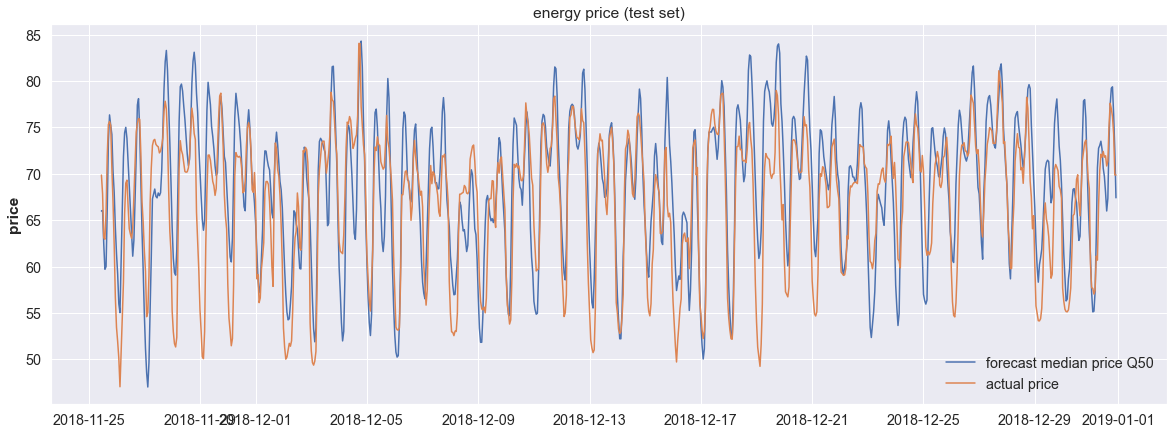

In [123]:
# plot the forecast
plt.figure(100, figsize=(20, 7))
sns.set(font_scale=1.3)
p = sns.lineplot(x = "time", y = "Q50", data = dfY, palette="coolwarm")
sns.lineplot(x = "time", y = "Actual", data = dfY, palette="coolwarm")
plt.legend(labels=["forecast median price Q50", "actual price"])
p.set_ylabel("price")
p.set_xlabel("")
p.set_title("energy price (test set)");

## 7.1. Прогноз вне выборки: 12 часов

Предположим, что мы хотим спрогнозировать почасовые цены на 12 часов, которые следуют за тестовым набором. Чтобы получить прогноз вне выборки, нам нужно предоставить признаки, которые охватывают расширенный горизонт прогнозирования.

Датированные признаки - часы, дни недели, месяцы и праздники - уже простираются до 01 января. Помните, что когда мы создавали их, перед обучением модели, мы добавили 48 часов после окончания фактических наблюдений.

Но нам также нужно придумать будущие значения для других признаков. Прогнозы погоды могут легко предоставить нам температуру и скорость ветра в течение следующих 12 часов. Для спроса на электроэнергию и производства электроэнергии нам придется получить одномерные прогнозы - либо с помощью классических моделей, таких как SARIMA; либо мы можем применить N-BEATS и к этим временным рядам (без признаков).

В этом упражнении мы предполагаем, что уже получили прогнозные значения для всех признаков. Мы просто копируем значения, которые были зарегистрированы за предыдущие 24 часа 31 декабря, и предполагаем, что погода, спрос и производство электроэнергии будут следовать тем же почасовым закономерностям 01 января, что и 31 декабря.

Затем мы вводим эти расширенные признаки в функцию `predict()`.


In [124]:
# choose forecast horizon: k hours beyond end of test set
k = 12   

n_FC = k + len(ts_ttest)   # length of test set + k hours
print("forecast beyond end of training set:", n_FC, 
      "hours beyond", ts_ttrain.end_time())

# last 24 hours of feature covariates available => copy them to future 24 hours:
covF_t_fut = covF_t.concatenate(    other=covF_t.tail(size=24), 
                                    ignore_time_axes=True)
# combine feature and time covariates:
cov_t_fut = covF_t_fut.concatenate(covT_t.slice_intersect(covF_t_fut), axis=1) 
cov_t_fut.pd_dataframe().iloc[[0,-1]]

forecast beyond end of training set: 888 hours beyond 2018-11-25 10:00:00+00:00


component,price_dayahead,gen_gas,gen_coal,temp_max_Seville,load_actual,temp_Seville,temp_min_Seville,temp_max_Madrid,temp_Madrid,temp_min_Barcelona,...,humidity_Madrid,wind_speed_Valencia,wind_speed_Madrid,gen_wind,gen_hyd_pump,hour,weekday,month,year,holidays
time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00+00:00,0.03,0.25,0.04,0.27,0.15,0.28,0.29,0.26,0.26,0.44,...,0.62,0.33,0.24,0.69,0.50,0.00,0.00,0.00,0.00,1.00
2019-01-01 22:00:00+00:00,0.76,0.52,0.24,0.30,0.26,0.29,0.27,0.15,0.16,0.17,...,0.72,0.13,0.06,0.22,0.03,0.96,0.17,0.00,1.00,1.00


In [125]:
# forecast from end of training set until k hours beyond end of test set
ts_tpred = model.predict(   n=n_FC, 
                            past_covariates=cov_t_fut, 
                            num_samples=N_SAMPLES, 
                            verbose=True, 
                            n_jobs=N_JOBS)
print("start:", ts_tpred.start_time(), "; end:",ts_tpred.end_time())


Predicting: 123it [00:00, ?it/s]

start: 2018-11-25 11:00:00+00:00 ; end: 2019-01-01 10:00:00+00:00


После того, как мы предоставили признаки, сценарий для вневыборочного прогноза практически идентичен сценарию тестовой фазы. Мы получаем датафрейм результатов dfY, который включает в себя прогноз для тестового набора, но теперь расширенный на 12 строк до 01 января 10:00.

In [126]:
# retrieve forecast series for chosen quantiles, 
# inverse-transform each series,
# insert them as columns in a new dataframe dfY
q50_RMSE = np.inf
q50_MAPE = np.inf
ts_q50 = None
pd.options.display.float_format = '{:,.2f}'.format
dfY = pd.DataFrame()
#dfY["Actual"] = TimeSeries.pd_series(ts_test)
 
# call helper function predQ, once for every quantile
_ = [predQ(ts_tpred, q) for q in QUANTILES]

# move Q50 column to the left, then insert Actual column
col = dfY.pop("Q50")
dfY.insert(0, col.name, col)
dfY.insert(0, "Actual", TimeSeries.pd_series(ts_test))

# show first and last 13 timestamps of forecast
dfY.iloc[np.r_[0:1, -13:0]]  

RMSE: 4.96
MAPE: 5.83


,Actual,Q50,Q01,Q10,Q20,Q80,Q90,Q99
time,,,,,,,,
2018-11-25 11:00:00+00:00,69.87,66.00,65.12,65.12,66.00,68.47,68.63,68.68
2018-12-31 22:00:00+00:00,69.88,67.56,62.82,66.49,67.02,69.49,70.01,70.76
2018-12-31 23:00:00+00:00,nan,63.14,60.57,62.08,62.36,64.52,65.46,67.74
2019-01-01 00:00:00+00:00,nan,58.77,56.95,57.80,58.21,60.48,60.94,63.61
2019-01-01 01:00:00+00:00,nan,57.55,55.64,56.71,57.07,59.10,59.57,65.76
2019-01-01 02:00:00+00:00,nan,56.91,51.11,55.47,56.07,58.60,59.14,64.66
2019-01-01 03:00:00+00:00,nan,58.51,56.31,57.37,57.74,59.88,60.52,62.00
2019-01-01 04:00:00+00:00,nan,61.11,58.87,59.98,60.44,62.35,62.86,64.27
2019-01-01 05:00:00+00:00,nan,64.37,62.24,63.01,63.60,66.18,66.78,68.53


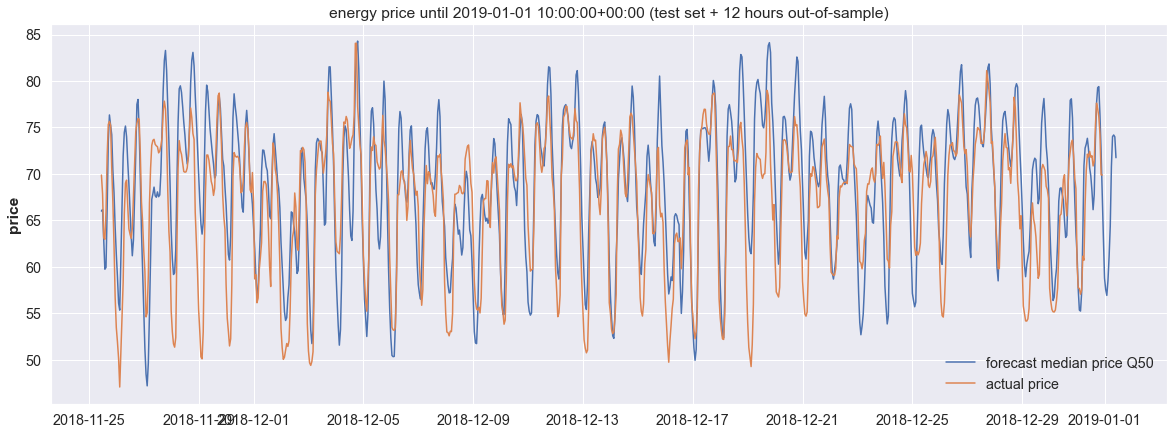

In [127]:
# plot the forecast
plt.figure(100, figsize=(20, 7))
sns.set(font_scale=1.3)
p = sns.lineplot(x = "time", y = "Q50", data = dfY, palette="coolwarm")
sns.lineplot(x = "time", y = "Actual", data = dfY, palette="coolwarm")
plt.legend(labels=["forecast median price Q50", "actual price"])
p.set_ylabel("price")
p.set_xlabel("")
end = ts_tpred.end_time()
p.set_title("energy price until {} (test set + {} hours out-of-sample)".format(end, k));

## 7.2. Прогноз вне выборки, ограниченный длиной выходных данных

При настройке модели используется необязательный аргумент `output_chunk_length`, по умолчанию установленный на 1, который мы оставили без изменений в нашем параметре `N_FC`. Таким образом, мы обучали модель прогнозирования с опережением на 1 шаг.

Если бы мы увеличили `output_chunk_length` до 12, прогноз вне выборки мог бы охватить 12 часов, не требуя от нас предоставления будущих признаков в качестве входных данных.

Вместо того чтобы прогнозировать 12 часов вне выборки, давайте попробуем это сделать, спрогнозировав цену на электроэнергию всего на один час после окончания тестового набора. Поскольку мы обучили модель на длине `output_chunk_length=1`, мы можем предсказать следующий час без повторного обучения.

Теперь мы ограничим признаки доступными фактическими исходными данными: `cov_t`.

In [128]:
# out-of-sample forecast just as long as output chunk length = 1

ts_tpred = model.predict(   n=len(ts_ttest) + 1, 
                            past_covariates=cov_t, 
                            num_samples=N_SAMPLES, 
                            verbose=True, 
                            n_jobs=N_JOBS)
print("start:", ts_tpred.start_time(), "; end:",ts_tpred.end_time())


q50_RMSE = np.inf
q50_MAPE = np.inf
ts_q50 = None
pd.options.display.float_format = '{:,.2f}'.format
dfY = pd.DataFrame()
#dfY["Actual"] = TimeSeries.pd_series(ts_test)
 
# call helper function predQ, once for every quantile
_ = [predQ(ts_tpred, q) for q in QUANTILES]

# move Q50 column to the left, then insert Actual column
col = dfY.pop("Q50")
dfY.insert(0, col.name, col)
dfY.insert(0, "Actual", TimeSeries.pd_series(ts_test))

# show first and last 13 timestamps of forecast
dfY.iloc[np.r_[0:1, -13:0]]  

Predicting: 123it [00:00, ?it/s]

start: 2018-11-25 11:00:00+00:00 ; end: 2018-12-31 23:00:00+00:00
RMSE: 4.96
MAPE: 5.83


,Actual,Q50,Q01,Q10,Q20,Q80,Q90,Q99
time,,,,,,,,
2018-11-25 11:00:00+00:00,69.87,66.00,61.49,65.12,66.00,68.47,68.47,68.68
2018-12-31 11:00:00+00:00,72.42,70.46,68.98,69.54,70.05,71.86,72.47,78.19
2018-12-31 12:00:00+00:00,71.80,69.80,67.86,69.07,69.29,71.63,72.23,72.60
2018-12-31 13:00:00+00:00,71.95,68.19,63.22,67.11,67.56,69.68,70.55,71.15
2018-12-31 14:00:00+00:00,70.85,65.91,61.03,64.91,65.32,67.24,68.10,70.18
2018-12-31 15:00:00+00:00,71.36,67.47,65.09,66.05,66.34,69.34,70.13,75.32
2018-12-31 16:00:00+00:00,75.13,73.32,70.76,71.88,72.69,74.24,75.38,76.62
2018-12-31 17:00:00+00:00,77.61,77.50,75.57,76.11,77.11,79.13,79.48,85.60
2018-12-31 18:00:00+00:00,77.02,79.28,77.32,78.42,78.98,80.53,81.11,81.63


Как и предполагалось, мы получаем прогноз на первый час после окончания фактических наблюдений.

Естественно, мы не можем поднять `output_chunk_length` до произвольного уровня. Более высокий уровень увеличит (экспоненциально) размер тензоров, использование памяти и время обработки. Размер выходных данных также не должен превышать длину `input_chunk_length`. Таким образом, прогнозирование вне выборки без предоставления будущих значений признаков возможно только для относительно коротких временных окон, ограниченных размером входного слоя.

# Выводы
Глубокие нейронные сети могут обрабатывать временные ряды, которые подвержены влиянию экзогенных переменных и демонстрируют сезонные колебания нескольких порядков - сочетание, которое превышает возможности большинства классических методов прогнозирования.

N-BEATS достиг MAPE в 5,83% (без каких-либо усилий по настройке). 